# Lab 4 — wczytanie danych

Funkcja przyjmuje ścieżkę do rozpakowanego folderu zadania. Nazwy podfolderów
(np. `nv`, `vasc`, `bkl`) określają klasy. Obrazy są skalowane do 128×128,
konwertowane do RGB i normalizowane do `[0, 1]`. Podział train/test zachowuje proporcje klas.


In [15]:
from pathlib import Path

import cv2
import numpy as np
from sklearn.model_selection import train_test_split

In [16]:
def load_dataset(task_path, image_size=(128, 128), test_size=0.2, random_state=42):
    """Wczytaj obrazy RGB w [0, 1]; zwróć train/test i mapowanie klas."""
    class_dirs = sorted(Path(task_path).iterdir())
    class_to_label = {p.name: i for i, p in enumerate(class_dirs)}
    images, labels = [], []

    for class_dir in class_dirs:
        for image_path in sorted(class_dir.glob('*.jpg')):
            image = cv2.imread(str(image_path))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, image_size, interpolation=cv2.INTER_AREA)
            images.append(image)
            labels.append(class_to_label[class_dir.name])

    X = np.asarray(images, dtype=np.float32) / 255.0
    y = np.asarray(labels, dtype=np.int64)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )
    return X_train, X_test, y_train, y_test, class_to_label


## Wczytanie obu zadań

Uruchom notebook z katalogu `lab4`. Funkcja wczytuje pliki `.jpg` z podfolderów klas.
Domyślny podział to 80% train i 20% test. Parametry możesz zmienić,
podając np. `image_size=(64, 64), test_size=0.25`.


In [17]:
X_train_1, X_test_1, y_train_1, y_test_1, labels_1 = load_dataset(
    'Task 1 - Simple'
)
X_train_2, X_test_2, y_train_2, y_test_2, labels_2 = load_dataset(
    'Task 2 - Hard'
)

for name, X_train, X_test, y_train, y_test, labels in [
    ('Task 1', X_train_1, X_test_1, y_train_1, y_test_1, labels_1),
    ('Task 2', X_train_2, X_test_2, y_train_2, y_test_2, labels_2),
]:
    print(f'{name}: etykiety {labels}')
    print(f'  train: X={X_train.shape}, y={y_train.shape}')
    print(f'  test:  X={X_test.shape}, y={y_test.shape}')


Task 1: etykiety {'nv': 0, 'vasc': 1}
  train: X=(227, 128, 128, 3), y=(227,)
  test:  X=(57, 128, 128, 3), y=(57,)
Task 2: etykiety {'bkl': 0, 'nv': 1}
  train: X=(1600, 128, 128, 3), y=(1600,)
  test:  X=(400, 128, 128, 3), y=(400,)


## Segmentacja na podstawie kolorów superpikseli

SLIC dzieli obraz na superpiksele. Ich średnie kolory grupujemy przez K-means
na dwie klasy w przestrzeni Lab. Ciemniejsza grupa jest oznaczana jako zmiana
(`True`), jaśniejsza jako tło (`False`). Wybór ciemniejszej grupy jest heurystyką.


In [18]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage.color import rgb2lab
from skimage.segmentation import mark_boundaries, slic
from skimage.util import img_as_float32


def segment_superpixels(image, n_segments=200, compactness=10, random_state=42):
    image = img_as_float32(image)
    superpixels = slic(
        image, n_segments=n_segments, compactness=compactness,
        sigma=1, start_label=0, channel_axis=-1
    )

    ids = superpixels.ravel()
    sizes = np.bincount(ids)
    mean_colors = np.column_stack([
        np.bincount(ids, weights=image[:, :, channel].ravel()) / sizes
        for channel in range(3)
    ])

    colors_lab = rgb2lab(mean_colors[np.newaxis, :, :])[0]
    model = KMeans(n_clusters=2, random_state=random_state, n_init=10)
    model.fit(colors_lab, sample_weight=sizes)
    lesion_label = np.argmin(model.cluster_centers_[:, 0])

    mask = model.labels_[superpixels] == lesion_label
    return mask, superpixels, mean_colors[superpixels]

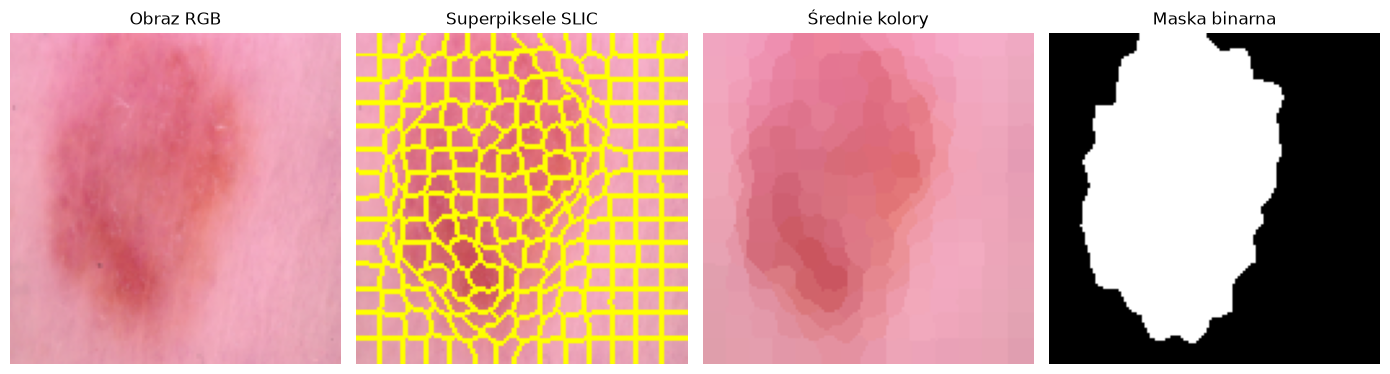

In [19]:
image = X_train_1[77]
mask, superpixels, superpixel_image = segment_superpixels(image)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(image)
axes[0].set_title('Obraz RGB')
axes[1].imshow(mark_boundaries(image, superpixels))
axes[1].set_title('Superpiksele SLIC')
axes[2].imshow(superpixel_image)
axes[2].set_title('Średnie kolory')
axes[3].imshow(mask, cmap='gray', vmin=0, vmax=1)
axes[3].set_title('Maska binarna')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

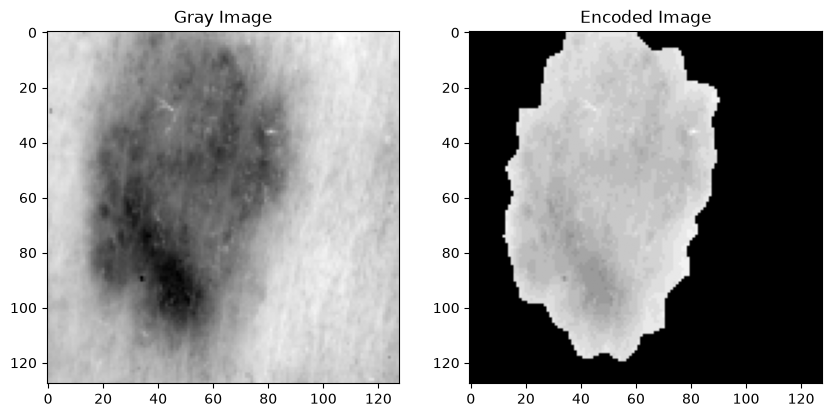

In [20]:
from skimage.util import img_as_float32
from skimage.color import rgb2gray

gray = rgb2gray(img_as_float32(image))
mask = np.asarray(mask, dtype=bool)
quantized = np.minimum((gray * 32).astype(np.int32), 32 - 1)

encoded = np.where(mask, quantized + 1, 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Gray Image')
axes[1].imshow(encoded, cmap='gray')
axes[1].set_title('Encoded Image')
plt.show()

In [24]:
import numpy as np
from skimage.color import rgb2gray, rgb2lab
from skimage.feature import graycomatrix, graycoprops
from skimage.measure import regionprops
from skimage.util import img_as_float32

def shape_features(mask):
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        raise ValueError("Maska jest pusta.")

    region = regionprops(mask.astype(np.uint8))[0]
    area = float(region.area)
    perimeter = float(region.perimeter)

    return {
        "shape_area": area,
        "shape_area_fraction": area / mask.size,
        "shape_perimeter": perimeter,
        "shape_circularity": 4 * np.pi * area / max(perimeter**2, 1e-12),
        "shape_eccentricity": float(region.eccentricity),
        "shape_solidity": float(region.solidity),
        "shape_extent": float(region.extent),
        "shape_major_axis": float(region.axis_major_length),
        "shape_minor_axis": float(region.axis_minor_length),
        "shape_axis_ratio": (
            region.axis_minor_length / max(region.axis_major_length, 1e-12)
        ),
    }


def color_features(image, mask):
    image = img_as_float32(image)
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        raise ValueError("Maska jest pusta.")

    features = {}
    for pixels, channels in [
        (image[mask], ("R", "G", "B")),
        (rgb2lab(image)[mask], ("L", "a", "b")),
    ]:
        for index, channel in enumerate(channels):
            values = pixels[:, index]
            features[f"color_{channel}_mean"] = float(values.mean())
            features[f"color_{channel}_std"] = float(values.std())

    return features


def texture_features(
    image,
    mask,
    levels=32,
    distances=(1, 2),
    angles=(0, np.pi / 4, np.pi / 2, 3 * np.pi / 4),
):
    gray = rgb2gray(img_as_float32(image))
    mask = np.asarray(mask, dtype=bool)
    quantized = np.minimum((gray * levels).astype(np.int32), levels - 1)

    encoded = np.where(mask, quantized + 1, 0)

    glcm = graycomatrix(
        encoded,
        distances=list(distances),
        angles=list(angles),
        levels=levels + 1,
        symmetric=True,
        normed=False,
    )

    glcm = glcm[1:, 1:, :, :].astype(np.float64)
    totals = glcm.sum(axis=(0, 1))
    valid = totals > 0

    if not valid.any():
        raise ValueError("Brak par pikseli wewnątrz maski dla podanych przesunięć.")

    glcm /= np.maximum(totals, 1)[None, None, :, :]

    features = {
        f"glcm_{prop}": float(graycoprops(glcm, prop)[valid].mean())
        for prop in (
            "contrast",
            "dissimilarity",
            "homogeneity",
            "energy",
            "correlation",
            "ASM",
        )
    }

    entropy = -np.sum(
        glcm * np.log2(np.clip(glcm, 1e-12, 1)),
        axis=(0, 1),
    )
    features["glcm_entropy"] = float(entropy[valid].mean())
    return features


def extract_features(image) -> np.ndarray:
    mask, _, _ = segment_superpixels(image) 

    features = {
        **shape_features(mask),
        **color_features(image, mask),
        **texture_features(image, mask),
    }
    return np.array(list(features.values()), dtype=np.float32)

In [52]:
image = X_train_1[0]
mask, _, _ = segment_superpixels(image)

feature_names = [
    *shape_features(mask),
    *color_features(image, mask),
    *texture_features(image, mask),
]

In [46]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

def encode(X):
    return np.array([extract_features(img) for img in X])

def make_pipeline():
    return Pipeline([
        ("features", FunctionTransformer(encode, validate=False)),
        ("classifier", RandomForestClassifier())
    ])

In [53]:
model_1 = make_pipeline()

In [54]:
model_1.fit(X_train_1, y_train_1)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,128
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function enc...x7f9ff2148b80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [55]:
y_pred_1 = model_1.predict(X_test_1)

              precision    recall  f1-score   support

           0       1.00      0.90      0.95        29
           1       0.90      1.00      0.95        28

    accuracy                           0.95        57
   macro avg       0.95      0.95      0.95        57
weighted avg       0.95      0.95      0.95        57



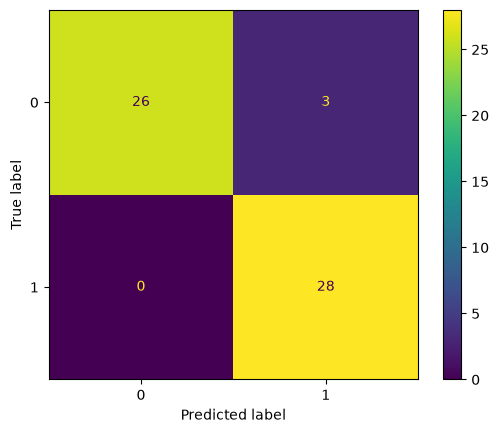

In [56]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(classification_report(y_test_1, y_pred_1))
cm = confusion_matrix(y_test_1, y_pred_1)
ConfusionMatrixDisplay(cm).plot()

In [63]:
def plot_feature_importance(model, feature_names):
    importance = pd.Series(
        model.named_steps["classifier"].feature_importances_,
        index=feature_names,
    ).sort_values(ascending=False)
    print(importance)
    importance.head(15).sort_values().plot.barh(figsize=(8, 6))
    plt.xlabel("Feature importance")
    plt.tight_layout()
    plt.show()

color_b_mean           0.306436
color_a_std            0.143114
color_B_mean           0.105311
color_a_mean           0.050658
shape_circularity      0.032093
color_R_mean           0.030673
color_L_mean           0.023547
shape_major_axis       0.023232
shape_area_fraction    0.019602
color_G_std            0.019440
color_b_std            0.019421
shape_perimeter        0.019228
shape_area             0.018618
color_B_std            0.018473
color_R_std            0.018182
shape_solidity         0.016249
color_G_mean           0.015922
color_L_std            0.014310
glcm_ASM               0.012034
shape_extent           0.011689
shape_minor_axis       0.011634
glcm_contrast          0.010658
glcm_correlation       0.010575
glcm_energy            0.009480
glcm_dissimilarity     0.008925
glcm_homogeneity       0.008841
shape_axis_ratio       0.008400
shape_eccentricity     0.007488
glcm_entropy           0.005766
dtype: float64


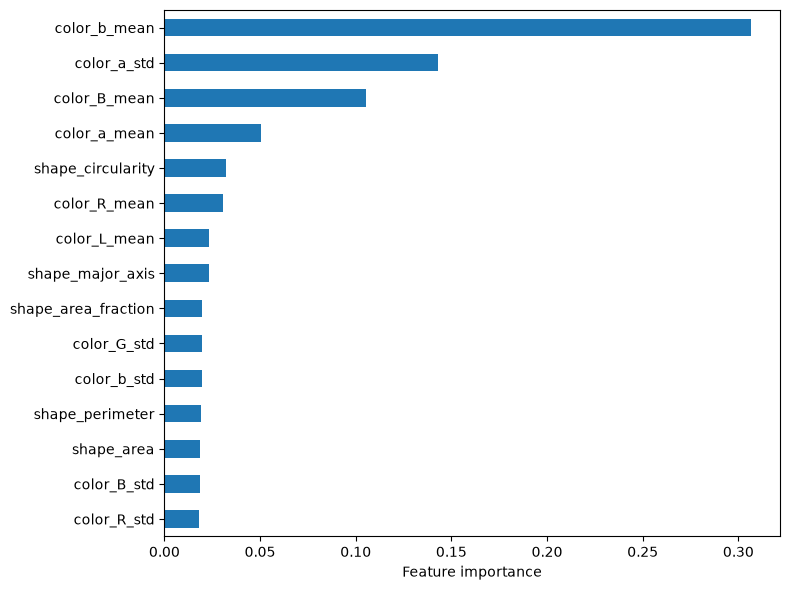

In [64]:
plot_feature_importance(model_1, feature_names)

In [59]:
model_2 = make_pipeline()

In [60]:
model_2.fit(X_train_2, y_train_2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,128
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function enc...x7f9ff2148b80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [61]:
y_pred_2 = model_2.predict(X_test_2)

              precision    recall  f1-score   support

           0       0.83      0.88      0.85       200
           1       0.87      0.82      0.85       200

    accuracy                           0.85       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.85      0.85      0.85       400



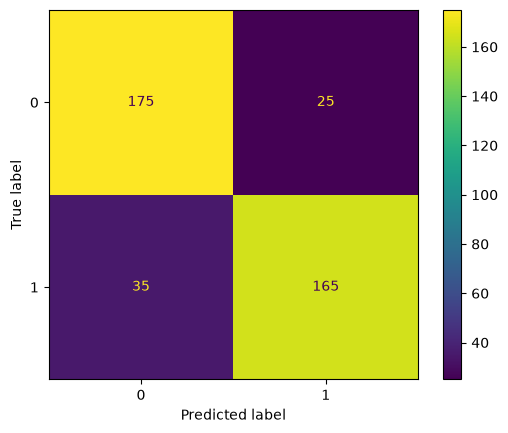

In [62]:
print(classification_report(y_test_2, y_pred_2))
cm = confusion_matrix(y_test_2, y_pred_2)
ConfusionMatrixDisplay(cm).plot()

color_a_mean           0.177232
color_b_mean           0.078808
shape_circularity      0.078495
shape_perimeter        0.058463
shape_solidity         0.057364
shape_extent           0.047742
color_B_mean           0.040823
shape_minor_axis       0.038491
color_G_mean           0.036248
shape_major_axis       0.034504
color_R_mean           0.033696
glcm_correlation       0.025309
color_a_std            0.022628
color_b_std            0.019984
color_L_mean           0.019605
color_G_std            0.019285
color_B_std            0.018902
glcm_contrast          0.018151
glcm_dissimilarity     0.017618
color_L_std            0.017503
color_R_std            0.017493
shape_area_fraction    0.016937
shape_axis_ratio       0.015679
glcm_entropy           0.015624
glcm_energy            0.015283
glcm_ASM               0.015063
glcm_homogeneity       0.014581
shape_eccentricity     0.014486
shape_area             0.014003
dtype: float64


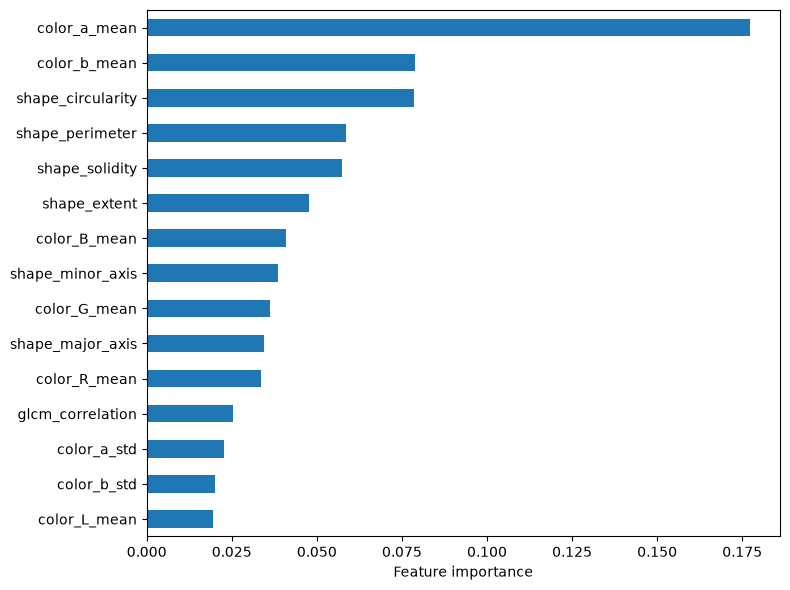

In [65]:
plot_feature_importance(model_2, feature_names)

## Rozpoznawanie 3 klas na raz

In [66]:
from hashlib import sha256

labels = {"nv": 0, "vasc": 1, "bkl": 2}

def remap_labels(y, old_labels):
    mapping = {number: labels[name] for name, number in old_labels.items()}
    return np.array([mapping[number] for number in y])


X = np.concatenate([X_train_1, X_train_2])
y = np.concatenate([
    remap_labels(y_train_1, labels_1),
    remap_labels(y_train_2, labels_2),
])

# Usuń duplikaty przed podziałem, aby nie trafiły jednocześnie do train i test.
hashes = [sha256(image.tobytes()).hexdigest() for image in X]
_, indices = np.unique(hashes, return_index=True)
indices.sort()

X = X[indices]
y = y[indices]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Etykiety:", labels)
print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Etykiety: {'nv': 0, 'vasc': 1, 'bkl': 2}
Train: (1388, 128, 128, 3) (1388,)
Test: (347, 128, 128, 3) (347,)


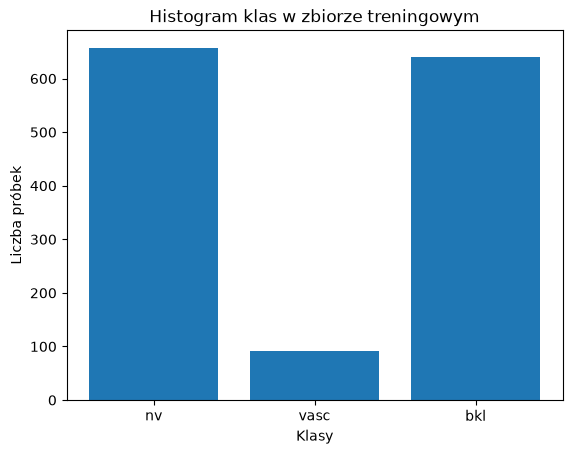

In [74]:
# histogram klas
plt.hist(y_train, bins=np.arange(len(labels) + 1) - 0.5, rwidth=0.8)
plt.xticks(range(len(labels)), labels.keys())
plt.xlabel("Klasy")
plt.ylabel("Liczba próbek")
plt.title("Histogram klas w zbiorze treningowym")
plt.show()

In [67]:
model_3 = make_pipeline()

In [68]:
model_3.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,128
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function enc...x7f9ff2148b80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [69]:
y_pred_3 = model_3.predict(X_test)

              precision    recall  f1-score   support

           0       0.78      0.81      0.79       164
           1       0.93      0.61      0.74        23
           2       0.78      0.78      0.78       160

    accuracy                           0.78       347
   macro avg       0.83      0.73      0.77       347
weighted avg       0.79      0.78      0.78       347



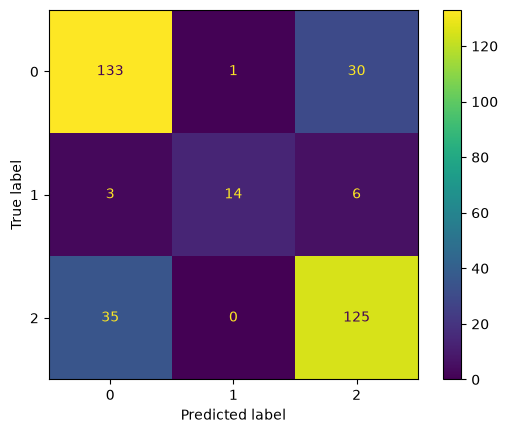

In [72]:
print(classification_report(y_test, y_pred_3))
cm = confusion_matrix(y_test, y_pred_3)
ConfusionMatrixDisplay(cm).plot()

color_a_mean           0.177232
color_b_mean           0.078808
shape_circularity      0.078495
shape_perimeter        0.058463
shape_solidity         0.057364
shape_extent           0.047742
color_B_mean           0.040823
shape_minor_axis       0.038491
color_G_mean           0.036248
shape_major_axis       0.034504
color_R_mean           0.033696
glcm_correlation       0.025309
color_a_std            0.022628
color_b_std            0.019984
color_L_mean           0.019605
color_G_std            0.019285
color_B_std            0.018902
glcm_contrast          0.018151
glcm_dissimilarity     0.017618
color_L_std            0.017503
color_R_std            0.017493
shape_area_fraction    0.016937
shape_axis_ratio       0.015679
glcm_entropy           0.015624
glcm_energy            0.015283
glcm_ASM               0.015063
glcm_homogeneity       0.014581
shape_eccentricity     0.014486
shape_area             0.014003
dtype: float64


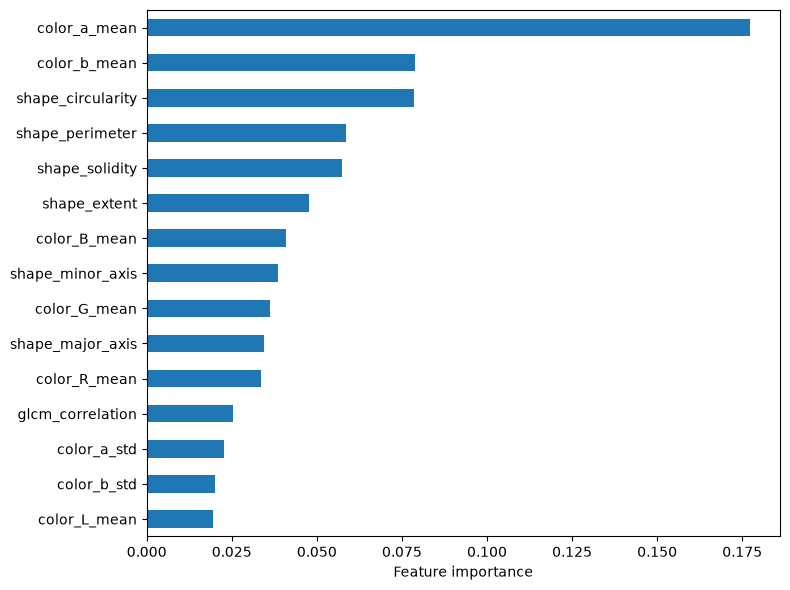

In [71]:
plot_feature_importance(model_2, feature_names)